# NN & DL: HW4
## Q1


## 1-1: Data prepration


### 1-1-1: load data set, report num of train and test data,seprate %10 of train data for validation


In [1]:
!pip install seqeval
!pip install kagglehub


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 1.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for seqeval: filename=seqeval-1.2.2-py3-none-any.whl size=16162 sha256=c73f90225613158b3c312117092f58742f3b49085e6defe66c6eeeca6e0bbef9
  Stored in directory: /root/.cache/pip/wheels/5f/b8/73/0b2c1a76b701a677653dd79ece07cfabd7457989dbfbdcd8d7
Successfully built seqeval


## imports


In [2]:
import kagglehub
import os
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import torch
from seqeval.metrics import classification_report, f1_score
import torch.nn as nn
import torch.optim as optim
import time
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence,pad_sequence
from torch.utils.data import Dataset, DataLoader
import random


In [3]:
# Download Dataset
print("Downloading ATIS dataset...")
path = kagglehub.dataset_download("siddhadev/atis-dataset-clean")
print("Path to dataset files:", path)

# Load Data:look for csv files in the downloaded directory
train_df_full = pd.read_csv(os.path.join(path, "atis.train.csv"))
test_df = pd.read_csv(os.path.join(path, "atis.test.csv"))

# Separate 10% for Validation
train_df, val_df = train_test_split(train_df_full, test_size=0.1, random_state=42)

#Report Numbers
print(f"--- Dataset Statistics ---")
print(f"Train samples: {len(train_df)}")
print(f"Validation samples: {len(val_df)}")
print(f"Test samples: {len(test_df)}")


Using Colab cache for faster access to the 'atis-dataset-clean' dataset.
Path to dataset files: /kaggle/input/atis-dataset-clean
--- Dataset Statistics ---
Train samples: 3846
Validation samples: 428
Test samples: 586


### 1-1-2: Check the dataset, show a sample of training data: the original sentence, slot labels, intent labels


In [4]:
# Select the first sample from the training set
sample = train_df.iloc[0]

# Identify column names
print(f"Dataset Columns: {train_df.columns.tolist()}")

# Extract values
sent_col = 'tokens' if 'tokens' in train_df.columns else train_df.columns[0]
slot_col = 'slots' if 'slots' in train_df.columns else train_df.columns[1]
intent_col = 'intent' if 'intent' in train_df.columns else train_df.columns[2]

print(f"\n--- Sample Data (Index 0) ---")
print(f"Original Sentence: {sample[sent_col]}")
print(f"Slot Labels:       {sample[slot_col]}")
print(f"Intent Label:      {sample[intent_col]}")


Dataset Columns: ['id', 'tokens', 'slots', 'intent']

--- Sample Data (Index 0) ---
Original Sentence: BOS what flights are available from boston to denver on wednesday in early morning EOS
Slot Labels:       O O O O O O B-fromloc.city_name O B-toloc.city_name O B-depart_date.day_name O B-depart_time.period_of_day B-depart_time.period_of_day O
Intent Label:      atis_flight


### 1-1-3: tokenize the data set based on whitespace


In [5]:
def preprocess_data(df, sent_col, slot_col, intent_col):
    sentences = []
    slots = []
    intents = df[intent_col].tolist()

    for i, row in df.iterrows():
        # Tokenize Sentence (split by whitespace)
        if isinstance(row[sent_col], str):
            sentences.append(row[sent_col].strip().split())
        else:
            sentences.append(row[sent_col]) # Already a list

        # Tokenize Slots (split by whitespace)
        if isinstance(row[slot_col], str):
            slots.append(row[slot_col].strip().split())
        else:
            slots.append(row[slot_col]) #a list

    return sentences, slots, intents

# Apply to all sets
train_sentences, train_slots, train_intents = preprocess_data(train_df, sent_col, slot_col, intent_col)
val_sentences, val_slots, val_intents = preprocess_data(val_df, sent_col, slot_col, intent_col)
test_sentences, test_slots, test_intents = preprocess_data(test_df, sent_col, slot_col, intent_col)

print("Tokenization complete.")
print(f"Sample tokenized sentence: {train_sentences[0]}")


Tokenization complete.
Sample tokenized sentence: ['BOS', 'what', 'flights', 'are', 'available', 'from', 'boston', 'to', 'denver', 'on', 'wednesday', 'in', 'early', 'morning', 'EOS']


### 1-1-4: build your vocab. show num of vocab for train , slot, intent sentences.
add < PAD> and < UNK>
tell when to use these 2 tokens:
* When to use special tokens?:

  < PAD >:when stacking sentences of different lengths into one matrix (Batch)

  < UNK >: when the model encounters a word during testing that it didn't learn during training.


In [6]:

class Vocabulary:
    def __init__(self, tokens=None, is_label=False, specials=None):
        self.idx2token = {}
        self.token2idx = {}
        self.is_label = is_label

        #  Add Special Tokens
        if specials:
            # Allow custom specials (e.g., for Slots in Sec 1-4)
            for s in specials:
                self.add_token(s)
        elif not is_label:
            # Default for Words
            self.add_token('<PAD>')
            self.add_token('<UNK>')
        else:
            # Default for standard Labels (Intents)
            # For simple classification, PAD might not be strictly necessary in the label vocab, but it helps for consistent indexing.
            self.add_token('<PAD>')

        if tokens:
            for token in tokens:
                self.add_token(token)

    def add_token(self, token):
        if token not in self.token2idx:
            idx = len(self.idx2token)
            self.idx2token[idx] = token
            self.token2idx[token] = idx

    def __len__(self):
        return len(self.idx2token)

    def lookup_indices(self, tokens):
        # Convert list of words to list of IDs
        if self.is_label:
             return [self.token2idx.get(t, self.token2idx.get('<PAD>')) for t in tokens]
        # Use <UNK> if word is not found
        return [self.token2idx.get(t, self.token2idx.get('<UNK>')) for t in tokens]

    def lookup_tokens(self, indices):
        return [self.idx2token[idx] for idx in indices]

# Collect all tokens from TRAINING data only
all_words = [word for sent in train_sentences for word in sent]
all_slots = [slot for sent_slots in train_slots for slot in sent_slots]
# Intents are single labels, we treat them as a list of unique items
all_intents = list(set(train_intents))

# Build Vocabularies
# Words: Standard PAD/UNK
vocab_words = Vocabulary(all_words, is_label=False)
# Slots: Needs PAD, BOS, EOS ( for Section 1-4)
vocab_slots = Vocabulary(all_slots, is_label=True, specials=['<PAD>'])
# Intents: Standard
vocab_intents = Vocabulary(all_intents, is_label=True)

print(f"--- Vocabulary Sizes ---")
print(f"Word Vocab Size: {len(vocab_words)}")
print(f"Slot Vocab Size: {len(vocab_slots)}")
print(f"Intent Vocab Size: {len(vocab_intents)}")



--- Vocabulary Sizes ---
Word Vocab Size: 837
Slot Vocab Size: 102
Intent Vocab Size: 18


### 1-1-5: build data_set aand data_loader classes


In [7]:
class AtisDataset(Dataset):
    def __init__(self, sentences, slots, intents, vocab_words, vocab_slots, vocab_intents):
        self.sentences = sentences
        self.slots = slots
        self.intents = intents
        self.vocab_words = vocab_words
        self.vocab_slots = vocab_slots
        self.vocab_intents = vocab_intents

    def __len__(self):
        return len(self.sentences)

    def __getitem__(self, idx):
        #  Get Text
        sent_tokens = self.sentences[idx]
        slot_tokens = self.slots[idx]
        intent_label = self.intents[idx]

        # Convert to Indices
        sent_ids = self.vocab_words.lookup_indices(sent_tokens)
        slot_ids = self.vocab_slots.lookup_indices(slot_tokens)
        intent_id = self.vocab_intents.token2idx.get(intent_label)

        # Return Tensors
        return torch.tensor(sent_ids), torch.tensor(slot_ids), torch.tensor(intent_id)

def collate_fn(batch):
    """
    Pads the sentences and slots to the max length in this specific batch.
    """
    sentences, slots, intents = zip(*batch)

    # Calculate lengths for packing later
    lengths = torch.tensor([len(s) for s in sentences])

    # Pad with 0 (which is <PAD> index)
    padded_sentences = pad_sequence(sentences, batch_first=True, padding_value=0)
    padded_slots = pad_sequence(slots, batch_first=True, padding_value=0)

    intents = torch.stack(intents)

    return padded_sentences, padded_slots, lengths, intents

# Instantiate DataLoaders
BATCH_SIZE = 64
train_dataset = AtisDataset(train_sentences, train_slots, train_intents, vocab_words, vocab_slots, vocab_intents)
val_dataset = AtisDataset(val_sentences, val_slots, val_intents, vocab_words, vocab_slots, vocab_intents)
test_dataset = AtisDataset(test_sentences, test_slots, test_intents, vocab_words, vocab_slots, vocab_intents)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)


### 1-1-6: train data batch 1& 2, show , compare sentence length , and showtoken id and decoded with words

sentence length changed intrabatchs?
advantage to padding to the longest sentence length?

1. Sentence length changed intrabatch?
  
   Yes, 'collate_fn' adjusts width based on the longest sentence in that specific batch.
2. Advantage?
  Efficiency. We process fewer zeros. If we padded to the global max (e.g., 50) every time, small batches (e.g., length 10) would waste computation.
  


In [8]:
# Fetch Batches
data_iter = iter(train_loader)
batch1 = next(data_iter)
batch2 = next(data_iter)

b1_sent, b1_slots, b1_lens, b1_intents = batch1
b2_sent, b2_slots, b2_lens, b2_intents = batch2

#Compare Lengths
print(f"Batch 1 - Max Sentence Length: {b1_sent.shape[1]}")
print(f"Batch 2 - Max Sentence Length: {b2_sent.shape[1]}")

#Decode a Sample: we take first sample from Batch 1
idx = 0
raw_ids = b1_sent[idx]
slot_ids = b1_slots[idx]
intent_id = b1_intents[idx]

# Decode (skip padding 0s)
decoded_words = vocab_words.lookup_tokens([i.item() for i in raw_ids if i.item() != 0])
decoded_slots = vocab_slots.lookup_tokens([i.item() for i in slot_ids if i.item() != 0])
decoded_intent = vocab_intents.idx2token[intent_id.item()]

print(f"\n--- Decoded Sample ---")
print(f"Raw IDs: {raw_ids.tolist()}")
print(f"Words:   {' '.join(decoded_words)}")
print(f"Slots:   {' '.join(decoded_slots)}")
print(f"Intent:  {decoded_intent}")


Batch 1 - Max Sentence Length: 28
Batch 2 - Max Sentence Length: 24

--- Decoded Sample ---
Raw IDs: [2, 113, 63, 9, 214, 71, 59, 7, 230, 9, 268, 73, 339, 71, 84, 13, 207, 238, 16, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Words:   BOS i'd like to find a flight from tampa to montreal that makes a stop in new york EOS
Slots:   O O O O O O O O B-fromloc.city_name O B-toloc.city_name O O O O O B-stoploc.city_name I-stoploc.city_name O
Intent:  atis_flight


### 1-2: Base Models (16 Points)

### 1-2-1: Model Training
**Task:** Design two separate **BiRNN** networks:
1.  **Intent Detection:** The output should be a vector of size `num_intents` (Many-to-One).
2.  **Slot Filling:** The output should produce a slot label for each token (Many-to-Many).

**Constraints:**
* **Loss Calculation:** Do NOT calculate loss on padded tokens (use `ignore_index` or masking).
* Follow the Architecture and Hyperparameters tables below exactly.

| **Architecture** | **Hyperparameters** |
| :--- | :--- |
| 1. Embedding | `EMBED_DIM`: 128 |
| 2. RNN (Bi-directional) | `HIDDEN_DIM`: 128 |
| 3. Dropout | `BIDIRECTIONAL`: True |
| 4. Linear | `DROPOUT`: 0.5 |
| | `BATCH_SIZE`: 32 |
| | `NUM_EPOCHS`: 10 |
| | `LEARNING_RATE`: 0.001 |
| | `OPTIMIZER`: Adam |
| | `LOSS`: CrossEntropyLoss |


In [9]:
#  Define the BiRNN Model
class BiRNN(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, output_dim, dropout_rate, mode='intent'):
        """
        mode: 'intent' (Many-to-One) or 'slot' (Many-to-Many)
        """
        super(BiRNN, self).__init__()
        self.mode = mode

        # Embedding Layer
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)

        # Bi-directional RNN
        # batch_first=True expects input shape: (batch, seq_len, feature)
        self.rnn = nn.RNN(input_size=embed_dim,
                          hidden_size=hidden_dim,
                          batch_first=True,
                          bidirectional=True)

        #Dropout
        self.dropout = nn.Dropout(dropout_rate)

        # Linear Layer
        # Input to linear is hidden_dim * 2 because it's bidirectional
        self.fc = nn.Linear(hidden_dim * 2, output_dim)

    def forward(self, text, text_lengths):
        # text shape: [batch_size, seq_len]

        embedded = self.embedding(text)

        # Pack sequence to ignore padding during RNN processing
        packed_embedded = pack_padded_sequence(embedded, text_lengths.cpu(), batch_first=True, enforce_sorted=False)

        # RNN Forward
        packed_output, hidden = self.rnn(packed_embedded)

        # Unpack output (for slot filling)
        output, output_lengths = pad_packed_sequence(packed_output, batch_first=True)
        # output shape: [batch_size, seq_len, hidden_dim * 2]
        # hidden shape: [num_dir, batch_size, hidden_dim]

        if self.mode == 'intent':
            # Many-to-One
            # We construct the representation from the last hidden states of both directions
            # hidden[-2] is the last hidden state of the Forward direction
            # hidden[-1] is the last hidden state of the Backward direction
            hidden_cat = torch.cat((hidden[-2,:,:], hidden[-1,:,:]), dim=1)
            # hidden_cat shape: [batch_size, hidden_dim * 2]

            x = self.dropout(hidden_cat)
            return self.fc(x) # Output: [batch_size, num_intents]

        else:
            # Many-to-Many
            # We use the full output sequence
            x = self.dropout(output)
            return self.fc(x) # Output: [batch_size, seq_len, num_slots]

# Hyperparameters, Setup
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Constants from Table
EMBED_DIM = 128
HIDDEN_DIM = 128
DROPOUT = 0.5
BATCH_SIZE = 32
NUM_EPOCHS = 10
LEARNING_RATE = 0.001

# Re-create DataLoaders with the new Batch Size (32)
train_loader_32 = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn)
val_loader_32 = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)
test_loader_32 = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)

#Initialize Models
# Intent Model
intent_model = BiRNN(vocab_size=len(vocab_words),
                     embed_dim=EMBED_DIM,
                     hidden_dim=HIDDEN_DIM,
                     output_dim=len(vocab_intents),
                     dropout_rate=DROPOUT,
                     mode='intent').to(device)

# Slot Model
slot_model = BiRNN(vocab_size=len(vocab_words),
                   embed_dim=EMBED_DIM,
                   hidden_dim=HIDDEN_DIM,
                   output_dim=len(vocab_slots),
                   dropout_rate=DROPOUT,
                   mode='slot').to(device)

# Optimizers
optimizer_intent = optim.Adam(intent_model.parameters(), lr=LEARNING_RATE)
optimizer_slot = optim.Adam(slot_model.parameters(), lr=LEARNING_RATE)

# Loss Functions
# ignore_index=0 ensures we don't calculate loss on <PAD> tokens
criterion_intent = nn.CrossEntropyLoss() # Intents don't have padding in the target
criterion_slot = nn.CrossEntropyLoss(ignore_index=0)

print("Models initialized.")

# Training Function
def train_epoch(model, iterator, optimizer, criterion, mode='intent'):
    model.train()
    epoch_loss = 0
    epoch_acc = 0
    total_tokens = 0 # For slot accuracy normalization

    for batch in iterator:
        text, slots, lengths, intents = batch

        # Move to device
        text = text.to(device)
        slots = slots.to(device)
        intents = intents.to(device)

        optimizer.zero_grad()

        # Forward pass
        predictions = model(text, lengths)

        if mode == 'intent':
            # predictions: [batch_size, num_intents]
            # intents: [batch_size]
            loss = criterion(predictions, intents)

            # Accuracy Calculation
            max_preds = predictions.argmax(dim=1, keepdim=True).squeeze(1)
            correct = (max_preds == intents).sum().item()
            epoch_acc += correct / intents.shape[0]

        else:
            # predictions: [batch_size, seq_len, num_slots]
            # slots: [batch_size, seq_len]

            # Reshape for CrossEntropyLoss
            # Flatten to: [(batch_size * seq_len), num_slots]
            predictions = predictions.view(-1, predictions.shape[-1])
            slots = slots.view(-1)

            loss = criterion(predictions, slots)

            # Accuracy Calculation (ignoring pads)
            max_preds = predictions.argmax(dim=1, keepdim=True).squeeze(1)
            non_pad_elements = slots != 0
            correct = (max_preds[non_pad_elements] == slots[non_pad_elements]).sum().item()
            total_tokens += non_pad_elements.sum().item()
            epoch_acc += correct # Will normalize later

        loss.backward()

        # Gradient Clipping (Optional but good practice for RNNs)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5)

        optimizer.step()
        epoch_loss += loss.item()

    # Return average loss and acc
    if mode == 'slot':
        epoch_acc = epoch_acc / total_tokens
    else:
        epoch_acc = epoch_acc / len(iterator)

    return epoch_loss / len(iterator), epoch_acc

def evaluate(model, iterator, criterion, mode='intent'):
    model.eval()
    epoch_loss = 0
    epoch_acc = 0
    total_tokens = 0

    with torch.no_grad():
        for batch in iterator:
            text, slots, lengths, intents = batch
            text = text.to(device)
            slots = slots.to(device)
            intents = intents.to(device)

            predictions = model(text, lengths)

            if mode == 'intent':
                loss = criterion(predictions, intents)
                epoch_loss += loss.item()

                max_preds = predictions.argmax(dim=1, keepdim=True).squeeze(1)
                correct = (max_preds == intents).sum().item()
                epoch_acc += correct / intents.shape[0]
            else:
                predictions = predictions.view(-1, predictions.shape[-1])
                slots = slots.view(-1)
                loss = criterion(predictions, slots)
                epoch_loss += loss.item()

                max_preds = predictions.argmax(dim=1, keepdim=True).squeeze(1)
                non_pad_elements = slots != 0
                correct = (max_preds[non_pad_elements] == slots[non_pad_elements]).sum().item()
                total_tokens += non_pad_elements.sum().item()
                epoch_acc += correct

    if mode == 'slot':
        epoch_acc = epoch_acc / total_tokens
    else:
        epoch_acc = epoch_acc / len(iterator)

    return epoch_loss / len(iterator), epoch_acc

#Run Training
print("\n--- Training Intent Model ---")
train_losses_intent, val_losses_intent = [], []
train_accs_intent, val_accs_intent = [], []

for epoch in range(NUM_EPOCHS):
    train_loss, train_acc = train_epoch(intent_model, train_loader_32, optimizer_intent, criterion_intent, mode='intent')
    valid_loss, valid_acc = evaluate(intent_model, val_loader_32, criterion_intent, mode='intent')

    train_losses_intent.append(train_loss)
    val_losses_intent.append(valid_loss)
    train_accs_intent.append(train_acc)
    val_accs_intent.append(valid_acc)

    print(f'Epoch: {epoch+1:02} | Train Loss: {train_loss:.3f} | Val Loss: {valid_loss:.3f} | Val Acc: {valid_acc*100:.2f}%')

print("\n--- Training Slot Model ---")
train_losses_slot, val_losses_slot = [], []
train_accs_slot, val_accs_slot = [], []

for epoch in range(NUM_EPOCHS):
    train_loss, train_acc = train_epoch(slot_model, train_loader_32, optimizer_slot, criterion_slot, mode='slot')
    valid_loss, valid_acc = evaluate(slot_model, val_loader_32, criterion_slot, mode='slot')

    train_losses_slot.append(train_loss)
    val_losses_slot.append(valid_loss)
    train_accs_slot.append(train_acc)
    val_accs_slot.append(valid_acc)

    print(f'Epoch: {epoch+1:02} | Train Loss: {train_loss:.3f} | Val Loss: {valid_loss:.3f} | Val Acc: {valid_acc*100:.2f}%')


Using device: cuda
Models initialized.

--- Training Intent Model ---
Epoch: 01 | Train Loss: 0.909 | Val Loss: 0.575 | Val Acc: 86.31%
Epoch: 02 | Train Loss: 0.448 | Val Loss: 0.412 | Val Acc: 90.33%
Epoch: 03 | Train Loss: 0.285 | Val Loss: 0.371 | Val Acc: 91.44%
Epoch: 04 | Train Loss: 0.190 | Val Loss: 0.369 | Val Acc: 92.49%
Epoch: 05 | Train Loss: 0.140 | Val Loss: 0.302 | Val Acc: 93.15%
Epoch: 06 | Train Loss: 0.111 | Val Loss: 0.246 | Val Acc: 94.49%
Epoch: 07 | Train Loss: 0.064 | Val Loss: 0.238 | Val Acc: 93.90%
Epoch: 08 | Train Loss: 0.049 | Val Loss: 0.226 | Val Acc: 94.94%
Epoch: 09 | Train Loss: 0.042 | Val Loss: 0.243 | Val Acc: 93.82%
Epoch: 10 | Train Loss: 0.024 | Val Loss: 0.226 | Val Acc: 94.05%

--- Training Slot Model ---
Epoch: 01 | Train Loss: 1.026 | Val Loss: 0.361 | Val Acc: 92.93%
Epoch: 02 | Train Loss: 0.278 | Val Loss: 0.204 | Val Acc: 95.41%
Epoch: 03 | Train Loss: 0.172 | Val Loss: 0.150 | Val Acc: 96.52%
Epoch: 04 | Train Loss: 0.122 | Val Loss: 0

### 1-2-2: Model Evaluation

**Tasks:**
1.  **Plots:** Plot the **Loss** and **Accuracy** curves for both Training and Validation sets over epochs.
2.  **Intent Evaluation:** Report the **Accuracy** on the Test set. (Target: > 80%)
3.  **Slot Evaluation:** Report the **F1 Score** and **Classification Report** using the `seqeval` library. (Target: > 80%)

**Question:**
* Why is the `seqeval` library preferred over `sklearn` metrics for this specific task (Sequence Labeling)?


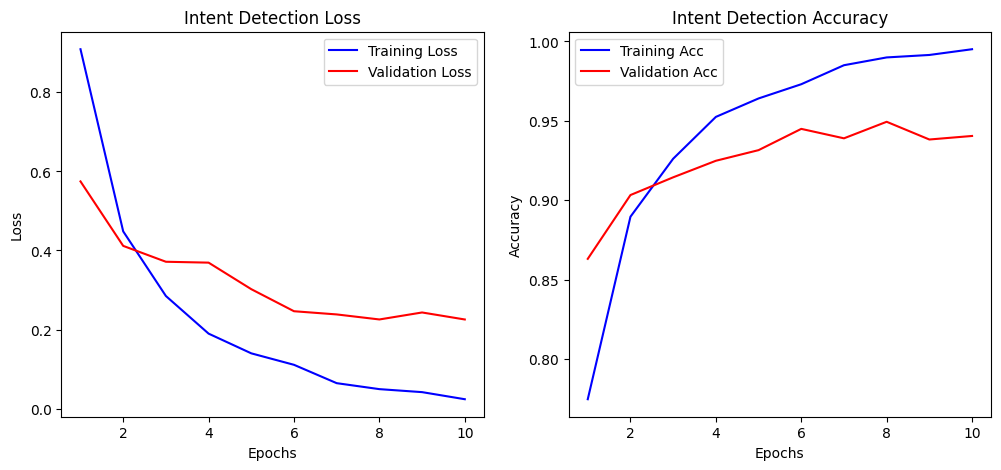

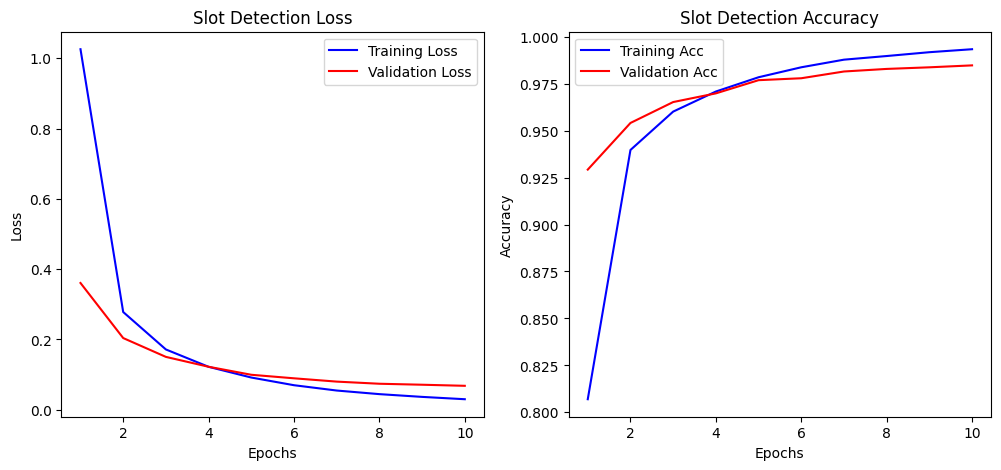


>> Intent Detection Test Accuracy: 96.05%

>> Slot Filling F1 Score: 94.64%

--- Classification Report ---
                            precision    recall  f1-score   support

             aircraft_code       0.71      0.71      0.71         7
              airline_code       1.00      0.91      0.95        22
              airline_name       0.98      0.99      0.98        91
              airport_code       0.38      0.75      0.50         4
              airport_name       0.44      0.50      0.47         8
 arrive_date.date_relative       0.00      0.00      0.00         1
      arrive_date.day_name       1.00      0.40      0.57        10
    arrive_date.day_number       1.00      0.86      0.92         7
    arrive_date.month_name       0.86      0.86      0.86         7
      arrive_time.end_time       1.00      0.67      0.80         3
    arrive_time.period_mod       0.00      0.00      0.00         1
 arrive_time.period_of_day       0.62      0.62      0.62         8
    arr

/usr/local/lib/python3.12/dist-packages/seqeval/metrics/v1.py:57: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [10]:
# Plotting Function
def plot_metrics(train_losses, val_losses, train_accs, val_accs, task_name="Intent"):
    epochs = range(1, len(train_losses) + 1)

    plt.figure(figsize=(12, 5))

    # Plot Loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs, train_losses, 'b-', label='Training Loss')
    plt.plot(epochs, val_losses, 'r-', label='Validation Loss')
    plt.title(f'{task_name} Detection Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    # Plot Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs, train_accs, 'b-', label='Training Acc')
    plt.plot(epochs, val_accs, 'r-', label='Validation Acc')
    plt.title(f'{task_name} Detection Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.show()

# ploting
plot_metrics(train_losses_intent, val_losses_intent, train_accs_intent, val_accs_intent, task_name="Intent")
plot_metrics(train_losses_slot, val_losses_slot, train_accs_slot, val_accs_slot, task_name="Slot")

# Evaluate Intent on Test Set
test_loss_intent, test_acc_intent = evaluate(intent_model, test_loader_32, criterion_intent, mode='intent')
print(f"\n>> Intent Detection Test Accuracy: {test_acc_intent*100:.2f}%")

# Evaluate Slots using seqeval
def get_slot_predictions_for_seqeval(model, iterator):
    model.eval()
    all_true_tags = []
    all_pred_tags = []

    with torch.no_grad():
        for batch in iterator:
            text, slots, lengths, intents = batch
            text = text.to(device)
            slots = slots.to(device)

            # getting the output of the model
            predictions = model(text, lengths) # Shape: [batch, seq_len, num_slots]
            predicted_ids = predictions.argmax(dim=2) # convert probib to intex

            # index 2 real tags (Decode)
            # remove paddings so that seqeval dont see them
            for i in range(slots.shape[0]): #looping on batches
                true_sent_tags = []
                pred_sent_tags = []

                # no-padding length
                length = lengths[i].item()

                for j in range(length):
                    # real tag
                    true_id = slots[i, j].item()
                    true_tag = vocab_slots.idx2token[true_id]

                    # pred tag
                    pred_id = predicted_ids[i, j].item()
                    pred_tag = vocab_slots.idx2token[pred_id]

                    true_sent_tags.append(true_tag)
                    pred_sent_tags.append(pred_tag)

                all_true_tags.append(true_sent_tags)
                all_pred_tags.append(pred_sent_tags)

    return all_true_tags, all_pred_tags

# get the predicted tags
true_tags, pred_tags = get_slot_predictions_for_seqeval(slot_model, test_loader_32)

# metric calc
f1 = f1_score(true_tags, pred_tags)
report = classification_report(true_tags, pred_tags)

print(f"\n>> Slot Filling F1 Score: {f1*100:.2f}%")
print("\n--- Classification Report ---")
print(report)


## 1-3: Joint Model

**Task:** Train a **Joint BiLSTM** model that simultaneously predicts Intents and Slots.

**Architecture:**
* **Shared Layers:** Embedding layer and BiLSTM layer are shared.
* **Heads:**
    1.  **Intent Head:** Takes the final hidden state of BiLSTM $\to$ Linear Layer $\to$ Intent Class.
    2.  **Slot Head:** Takes the complete sequence outputs of BiLSTM $\to$ Linear Layer $\to$ Slot Tags.
  

**Loss Function:**
$$Loss = Loss_{Intent} + Loss_{Slot}$$

**Hyperparameters:**
Same as previous section (Batch Size: 32, Embed: 128, Hidden: 128, etc.).


### 1-3-2: Model Evaluation

**Tasks:**
1.  **Plots:** Plot the **Loss** and **Accuracy** curves for both Training and Validation sets over epochs.
2.  **Intent Evaluation:** Report the **Accuracy** on the Test set. (Target: > 80%)
3.  **Slot Evaluation:** Report the **F1 Score** and **Classification Report** using the `seqeval` library. (Target: > 80%)


Joint Model Initialized.

--- Training Joint Model ---
Epoch: 01 | Loss: 2.601 | Val Loss: 1.271 | Val Intent Acc: 85.57% | Val Slot Acc: 84.45%
Epoch: 02 | Loss: 0.936 | Val Loss: 0.662 | Val Intent Acc: 92.93% | Val Slot Acc: 92.75%
Epoch: 03 | Loss: 0.524 | Val Loss: 0.490 | Val Intent Acc: 94.27% | Val Slot Acc: 94.71%
Epoch: 04 | Loss: 0.343 | Val Loss: 0.401 | Val Intent Acc: 94.27% | Val Slot Acc: 95.80%
Epoch: 05 | Loss: 0.235 | Val Loss: 0.309 | Val Intent Acc: 95.46% | Val Slot Acc: 96.59%
Epoch: 06 | Loss: 0.172 | Val Loss: 0.297 | Val Intent Acc: 95.68% | Val Slot Acc: 97.09%
Epoch: 07 | Loss: 0.126 | Val Loss: 0.283 | Val Intent Acc: 95.91% | Val Slot Acc: 97.34%
Epoch: 08 | Loss: 0.094 | Val Loss: 0.265 | Val Intent Acc: 95.46% | Val Slot Acc: 97.53%
Epoch: 09 | Loss: 0.077 | Val Loss: 0.252 | Val Intent Acc: 95.68% | Val Slot Acc: 97.88%
Epoch: 10 | Loss: 0.063 | Val Loss: 0.241 | Val Intent Acc: 96.13% | Val Slot Acc: 98.10%

--- Plotting Curves ---


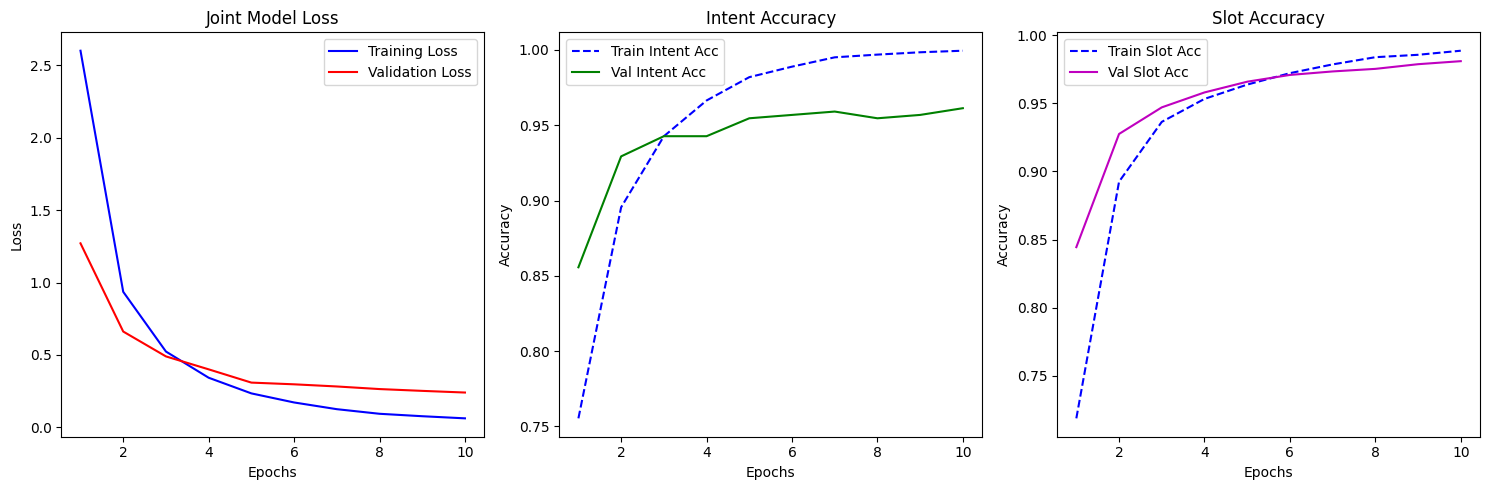


--- Test Set Evaluation ---
>> Joint Model Intent Accuracy: 97.10%
>> Joint Model Slot F1 Score: 93.26%

Classification Report:
                            precision    recall  f1-score   support

             aircraft_code       0.75      0.43      0.55         7
              airline_code       1.00      0.86      0.93        22
              airline_name       0.90      0.96      0.93        91
              airport_code       0.00      0.00      0.00         4
              airport_name       0.17      0.38      0.23         8
 arrive_date.date_relative       0.00      0.00      0.00         1
      arrive_date.day_name       1.00      0.70      0.82        10
    arrive_date.day_number       0.71      0.71      0.71         7
    arrive_date.month_name       1.00      1.00      1.00         7
      arrive_time.end_time       0.67      0.67      0.67         3
    arrive_time.period_mod       0.00      0.00      0.00         1
 arrive_time.period_of_day       0.71      0.62      0

In [11]:
#  Model Definition (Joint BiLSTM)
class JointBiLSTM(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_intents, num_slots, dropout_rate):
        super(JointBiLSTM, self).__init__()
        # Shared Encoder
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(dropout_rate)

        # Heads
        # Input to linear is hidden_dim * 2 because it's bidirectional
        self.fc_intent = nn.Linear(hidden_dim * 2, num_intents)
        self.fc_slot = nn.Linear(hidden_dim * 2, num_slots)

    def forward(self, text, text_lengths):
        #  Embed
        embedded = self.embedding(text)

        # Pack & LSTM
        packed_embedded = pack_padded_sequence(embedded, text_lengths.cpu(), batch_first=True, enforce_sorted=False)
        packed_output, (hidden, cell) = self.lstm(packed_embedded)
        output, _ = pad_packed_sequence(packed_output, batch_first=True)

        #  Slot Head (Many-to-Many)
        # Apply dropout to the full sequence output
        slot_logits = self.fc_slot(self.dropout(output))

        #  Intent Head (Many-to-One)
        # Concatenate the last hidden states of forward and backward directions
        # hidden shape: [num_layers * num_directions, batch, hidden_size]
        hidden_cat = torch.cat((hidden[-2,:,:], hidden[-1,:,:]), dim=1)
        intent_logits = self.fc_intent(self.dropout(hidden_cat))

        return intent_logits, slot_logits

# Initialization
# Re-using hyperparameters from Part 1-2 as requested
# Assumes EMBED_DIM, HIDDEN_DIM, DROPOUT, LEARNING_RATE are defined
joint_model = JointBiLSTM(vocab_size=len(vocab_words),
                          embed_dim=EMBED_DIM,
                          hidden_dim=HIDDEN_DIM,
                          num_intents=len(vocab_intents),
                          num_slots=len(vocab_slots),
                          dropout_rate=DROPOUT).to(device)

optimizer_joint = optim.Adam(joint_model.parameters(), lr=LEARNING_RATE)

# Loss Functions
# Intent: Standard Cross Entropy
criterion_intent = nn.CrossEntropyLoss()
# Slot: Cross Entropy ignoring padding
criterion_slot = nn.CrossEntropyLoss(ignore_index=0)

print("Joint Model Initialized.")

# Train & Eval Functions

def train_joint(model, iterator, optimizer, criterion_intent, criterion_slot):
    model.train()
    epoch_loss = 0
    epoch_acc_intent = 0
    epoch_acc_slot = 0
    total_tokens = 0

    for batch in iterator:
        text, slots, lengths, intents = batch
        text = text.to(device)
        slots = slots.to(device)
        intents = intents.to(device)

        optimizer.zero_grad()
        intent_preds, slot_preds = model(text, lengths)

        # Calculate Joint Loss
        loss_intent = criterion_intent(intent_preds, intents)

        # Flatten slots for CrossEntropy
        slot_preds_flat = slot_preds.view(-1, slot_preds.shape[-1])
        slots_flat = slots.view(-1)
        loss_slot = criterion_slot(slot_preds_flat, slots_flat)

        # Total Loss (Equal Weights)
        loss = loss_intent + loss_slot

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5)
        optimizer.step()
        epoch_loss += loss.item()

        # Accuracy Metrics for Monitoring
        # Intent Acc
        max_preds_i = intent_preds.argmax(dim=1)
        epoch_acc_intent += (max_preds_i == intents).sum().item() / intents.shape[0]

        # Slot Acc (ignoring pads)
        max_preds_s = slot_preds.argmax(dim=2)
        mask = slots != 0
        epoch_acc_slot += (max_preds_s[mask] == slots[mask]).sum().item()
        total_tokens += mask.sum().item()

    return epoch_loss / len(iterator), epoch_acc_intent / len(iterator), epoch_acc_slot / total_tokens

def evaluate_joint(model, iterator, criterion_intent, criterion_slot):
    model.eval()
    epoch_loss = 0
    epoch_acc_intent = 0
    epoch_acc_slot = 0
    total_tokens = 0

    with torch.no_grad():
        for batch in iterator:
            text, slots, lengths, intents = batch
            text = text.to(device)
            slots = slots.to(device)
            intents = intents.to(device)

            intent_preds, slot_preds = model(text, lengths)

            # Loss
            loss_intent = criterion_intent(intent_preds, intents)
            slot_preds_flat = slot_preds.view(-1, slot_preds.shape[-1])
            slots_flat = slots.view(-1)
            loss_slot = criterion_slot(slot_preds_flat, slots_flat)
            epoch_loss += (loss_intent + loss_slot).item()

            # Accuracy
            max_preds_i = intent_preds.argmax(dim=1)
            epoch_acc_intent += (max_preds_i == intents).sum().item() / intents.shape[0]

            max_preds_s = slot_preds.argmax(dim=2)
            mask = slots != 0
            epoch_acc_slot += (max_preds_s[mask] == slots[mask]).sum().item()
            total_tokens += mask.sum().item()

    return epoch_loss / len(iterator), epoch_acc_intent / len(iterator), epoch_acc_slot / total_tokens

# Training Loop
print("\n--- Training Joint Model ---")
train_losses = []
val_losses = []
# Lists for plotting
train_intent_accs, val_intent_accs = [], []
train_slot_accs, val_slot_accs = [], []

for epoch in range(NUM_EPOCHS):
    train_loss, train_acc_i, train_acc_s = train_joint(joint_model, train_loader_32, optimizer_joint, criterion_intent, criterion_slot)
    valid_loss, valid_acc_i, valid_acc_s = evaluate_joint(joint_model, val_loader_32, criterion_intent, criterion_slot)

    train_losses.append(train_loss)
    val_losses.append(valid_loss)

    train_intent_accs.append(train_acc_i)
    val_intent_accs.append(valid_acc_i)

    train_slot_accs.append(train_acc_s)
    val_slot_accs.append(valid_acc_s)

    print(f'Epoch: {epoch+1:02} | Loss: {train_loss:.3f} | Val Loss: {valid_loss:.3f} | Val Intent Acc: {valid_acc_i*100:.2f}% | Val Slot Acc: {valid_acc_s*100:.2f}%')

# Plotting Results
def plot_joint_metrics(train_losses, val_losses, train_intent_accs, val_intent_accs, train_slot_accs, val_slot_accs):
    epochs = range(1, len(train_losses) + 1)

    plt.figure(figsize=(15, 5))

    # Loss Plot
    plt.subplot(1, 3, 1)
    plt.plot(epochs, train_losses, 'b-', label='Training Loss')
    plt.plot(epochs, val_losses, 'r-', label='Validation Loss')
    plt.title('Joint Model Loss'); plt.xlabel('Epochs'); plt.ylabel('Loss'); plt.legend()

    # Intent Accuracy Plot
    plt.subplot(1, 3, 2)
    plt.plot(epochs, train_intent_accs, 'b--', label='Train Intent Acc')
    plt.plot(epochs, val_intent_accs, 'g-', label='Val Intent Acc')
    plt.title('Intent Accuracy'); plt.xlabel('Epochs'); plt.ylabel('Accuracy'); plt.legend()

    # Slot Accuracy Plot
    plt.subplot(1, 3, 3)
    plt.plot(epochs, train_slot_accs, 'b--', label='Train Slot Acc')
    plt.plot(epochs, val_slot_accs, 'm-', label='Val Slot Acc')
    plt.title('Slot Accuracy'); plt.xlabel('Epochs'); plt.ylabel('Accuracy'); plt.legend()

    plt.tight_layout()
    plt.show()

print("\n--- Plotting Curves ---")
plot_joint_metrics(train_losses, val_losses, train_intent_accs, val_intent_accs, train_slot_accs, val_slot_accs)

# Final Evaluation (Test Set)
def get_joint_predictions(model, iterator):
    model.eval()
    all_true_tags = []
    all_pred_tags = []
    total_intent_correct = 0
    total_intents = 0

    with torch.no_grad():
        for batch in iterator:
            text, slots, lengths, intents = batch
            text = text.to(device)
            slots = slots.to(device)
            intents = intents.to(device)

            # Get predictions
            intent_preds, slot_preds = model(text, lengths)

            #  Intent Eval
            max_preds_i = intent_preds.argmax(dim=1)
            total_intent_correct += (max_preds_i == intents).sum().item()
            total_intents += intents.shape[0]

            #  Slot Eval (Decoding for seqeval)
            predicted_ids = slot_preds.argmax(dim=2)
            for i in range(slots.shape[0]):
                true_sent_tags = []
                pred_sent_tags = []
                length = lengths[i].item()
                for j in range(length):
                    # Map IDs back to Tokens
                    true_tag = vocab_slots.idx2token[slots[i, j].item()]
                    pred_tag = vocab_slots.idx2token[predicted_ids[i, j].item()]

                    true_sent_tags.append(true_tag)
                    pred_sent_tags.append(pred_tag)

                all_true_tags.append(true_sent_tags)
                all_pred_tags.append(pred_sent_tags)

    return total_intent_correct / total_intents, all_true_tags, all_pred_tags

print("\n--- Test Set Evaluation ---")
test_intent_acc, true_tags, pred_tags = get_joint_predictions(joint_model, test_loader_32)

# Report Intent Accuracy
print(f">> Joint Model Intent Accuracy: {test_intent_acc*100:.2f}%")

# Report Slot F1
f1 = f1_score(true_tags, pred_tags)
print(f">> Joint Model Slot F1 Score: {f1*100:.2f}%")
print("\nClassification Report:")
print(classification_report(true_tags, pred_tags))


### 1-4: Encoder-Decoder non-aligned joint Model

In this section, we implement a **Sequence-to-Sequence (Seq2Seq)** architecture for Slot Filling. Unlike the previous parts where the input and output were aligned (1-to-1 mapping), here the Decoder generates the output sequence step-by-step based on the Encoder's context vector.



### 1-4-1: Model Implementation
**Task:** Implement three classes:
1.  **Encoder:** An LSTM that consumes the input sentence and produces a context vector (final hidden state).
2.  **Decoder:** An LSTM that takes the context vector and the previous output token to predict the next slot label.
    * *Input:* Previous generated token (or ground truth during training).
    * *Hidden:* Previous hidden state.
3.  **Seq2Seq:** A class to combine Encoder and Decoder.

**Constraints:**
* **Special Tokens:** must handle `<BOS>` (start of decoding) and `<EOS>` (end of decoding).
* **Teacher Forcing:** Implement Teacher Forcing with a ratio (e.g., 0.5) to speed up training.
* **Hyperparameters:** Embed Dim: 128, Hidden Dim: 128, Epochs: 50.



Step 1: Update Slot Vocabulary
Since the Decoder generates a sequence, it needs to know when to start (<BOS>) and stop (<EOS>). We didn add these to the Slot vocabulary earlier, but we still check, so we must add them now.


In [12]:
# Update Vocabulary :The Decoder needs <BOS> to start generating and <EOS> to stop.
if '<BOS>' not in vocab_slots.token2idx:
    print("Injecting <BOS> and <EOS> into vocab_slots...")
    vocab_slots.add_token('<BOS>')
    vocab_slots.add_token('<EOS>')
else:
    print("vocab_slots already contains <BOS> and <EOS>.")

print(f"Updated Slot Vocab Size: {len(vocab_slots)}")
print(f"<BOS> ID: {vocab_slots.token2idx['<BOS>']}")
print(f"<EOS> ID: {vocab_slots.token2idx['<EOS>']}")


Injecting <BOS> and <EOS> into vocab_slots...
Updated Slot Vocab Size: 104
<BOS> ID: 102
<EOS> ID: 103


Step 2: Define Encoder, Decoder, and Seq2Seq Classes
Copy this entire block. This implements the standard Sequence-to-Sequence architecture with Teacher Forcing.

The Encoder is Bi-directional (to capture full context), but the Decoder is Uni-directional (generation is sequential). We use a Linear layer to bridge the shape difference between them.


In [13]:
import torch.nn as nn
import torch.optim as optim

#Model Definitions (Encoder, Decoder, JointSeq2Seq)
class Encoder(nn.Module):
    def __init__(self, input_dim, emb_dim, hid_dim, dropout):
        super().__init__()
        self.embedding = nn.Embedding(input_dim, emb_dim, padding_idx=0)
        self.rnn = nn.LSTM(emb_dim, hid_dim, batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(dropout)

    def forward(self, src, src_len):
        embedded = self.dropout(self.embedding(src))
        packed_embedded = pack_padded_sequence(embedded, src_len.cpu(), batch_first=True, enforce_sorted=False)
        _, (hidden, cell) = self.rnn(packed_embedded)
        hidden_cat = torch.cat((hidden[-2,:,:], hidden[-1,:,:]), dim=1)
        cell_cat = torch.cat((cell[-2,:,:], cell[-1,:,:]), dim=1)
        return hidden_cat, cell_cat

class Decoder(nn.Module):
    def __init__(self, output_dim, emb_dim, hid_dim, dropout):
        super().__init__()
        self.output_dim = output_dim
        self.embedding = nn.Embedding(output_dim, emb_dim, padding_idx=0)
        self.rnn = nn.LSTM(emb_dim, hid_dim, batch_first=True, bidirectional=False)
        self.fc_out = nn.Linear(hid_dim, output_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, input, hidden, cell):
        input = input.unsqueeze(1)
        embedded = self.dropout(self.embedding(input))
        output, (hidden, cell) = self.rnn(embedded, (hidden.unsqueeze(0), cell.unsqueeze(0)))
        prediction = self.fc_out(output.squeeze(1))
        return prediction, hidden.squeeze(0), cell.squeeze(0)

class JointSeq2Seq(nn.Module):
    def __init__(self, encoder, decoder, device, num_intents):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.device = device
        self.intent_head = nn.Linear(encoder.rnn.hidden_size * 2, num_intents)

    def forward(self, src, src_len, trg, teacher_forcing_ratio=0.5):
        batch_size = src.shape[0]
        trg_len = trg.shape[1]
        trg_vocab_size = self.decoder.output_dim
        outputs = torch.zeros(batch_size, trg_len, trg_vocab_size).to(self.device)

        context_hidden, context_cell = self.encoder(src, src_len)
        intent_logits = self.intent_head(context_hidden)

        hidden = context_hidden
        cell = context_cell
        input = trg[:, 0]

        for t in range(1, trg_len):
            output, hidden, cell = self.decoder(input, hidden, cell)
            outputs[:, t, :] = output
            best_guess = output.argmax(1)
            input = trg[:, t] if random.random() < teacher_forcing_ratio else best_guess
        return outputs, intent_logits


Step 3: Initialization & Training Loop


In [14]:
# Hyperparameters & Init
INPUT_DIM = len(vocab_words)
OUTPUT_DIM = len(vocab_slots)
ENC_EMB_DIM = 128
ENC_HID_DIM = 128
DEC_EMB_DIM = 64
DEC_HID_DIM = 256
ENC_DROPOUT = 0.5
DEC_DROPOUT = 0.5
TEACHER_FORCING = 0.5
NUM_EPOCHS_S2S = 20

enc = Encoder(INPUT_DIM, ENC_EMB_DIM, ENC_HID_DIM, ENC_DROPOUT)
dec = Decoder(OUTPUT_DIM, DEC_EMB_DIM, DEC_HID_DIM, DEC_DROPOUT)
model_s2s = JointSeq2Seq(enc, dec, device, num_intents=len(vocab_intents)).to(device)

optimizer_s2s = optim.Adam(model_s2s.parameters(), lr=0.001)
criterion_slots = nn.CrossEntropyLoss(ignore_index=vocab_slots.token2idx['<PAD>'])
criterion_intent = nn.CrossEntropyLoss()

# Training & Validation Help Func

def train_epoch(model, iterator, optimizer, crit_slots, crit_intent, clip):
    model.train()
    epoch_loss = 0
    for batch in iterator:
        src, slots, lengths, intents = batch
        src, slots, intents = src.to(device), slots.to(device), intents.to(device)
        batch_size = src.shape[0]

        BOS_ID = vocab_slots.token2idx['<BOS>']
        EOS_ID = vocab_slots.token2idx['<EOS>']
        bos_tensor = torch.full((batch_size, 1), BOS_ID).to(device)
        eos_tensor = torch.full((batch_size, 1), EOS_ID).to(device)
        trg = torch.cat((bos_tensor, slots, eos_tensor), dim=1)

        optimizer.zero_grad()
        slot_outputs, intent_logits = model(src, lengths, trg, TEACHER_FORCING)

        output_dim = slot_outputs.shape[-1]
        slot_outputs = slot_outputs[:, 1:].reshape(-1, output_dim)
        trg_slots = trg[:, 1:].reshape(-1)
        loss_s = crit_slots(slot_outputs, trg_slots)
        loss_i = crit_intent(intent_logits, intents)
        loss = loss_s + loss_i

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
        optimizer.step()
        epoch_loss += loss.item()
    return epoch_loss / len(iterator)

def evaluate_epoch(model, iterator, crit_slots, crit_intent):
    model.eval()
    epoch_loss = 0
    total_intent_correct = 0
    total_intents = 0
    total_slots_correct = 0
    total_slots = 0

    with torch.no_grad():
        for batch in iterator:
            src, slots, lengths, intents = batch
            src, slots, intents = src.to(device), slots.to(device), intents.to(device)
            batch_size = src.shape[0]

            BOS_ID = vocab_slots.token2idx['<BOS>']
            EOS_ID = vocab_slots.token2idx['<EOS>']
            bos_tensor = torch.full((batch_size, 1), BOS_ID).to(device)
            eos_tensor = torch.full((batch_size, 1), EOS_ID).to(device)
            trg = torch.cat((bos_tensor, slots, eos_tensor), dim=1)

            # Teacher forcing = 0 for validation
            slot_outputs, intent_logits = model(src, lengths, trg, 0)

            # Loss
            output_dim = slot_outputs.shape[-1]
            loss_s = crit_slots(slot_outputs[:, 1:].reshape(-1, output_dim), trg[:, 1:].reshape(-1))
            loss_i = crit_intent(intent_logits, intents)
            epoch_loss += (loss_s + loss_i).item()

            # Accuracy
            # Intent
            pred_intents = intent_logits.argmax(dim=1)
            total_intent_correct += (pred_intents == intents).sum().item()
            total_intents += batch_size

            # Slots (Token Accuracy)
            pred_slots = slot_outputs.argmax(dim=2)[:, 1:] # Remove BOS
            trg_slots = trg[:, 1:] # Remove BOS

            # Mask padding
            mask = trg_slots != vocab_slots.token2idx['<PAD>']
            total_slots_correct += (pred_slots[mask] == trg_slots[mask]).sum().item()
            total_slots += mask.sum().item()

    return epoch_loss / len(iterator), total_intent_correct / total_intents, total_slots_correct / total_slots

# Main Loop (Training & Storing Metrics)
train_losses = []
val_losses = []
val_intent_accs = []
val_slot_accs = []

print("Start Training Joint Seq2Seq...")
for epoch in range(NUM_EPOCHS_S2S):
    train_l = train_epoch(model_s2s, train_loader_32, optimizer_s2s, criterion_slots, criterion_intent, clip=5)
    val_l, val_i_acc, val_s_acc = evaluate_epoch(model_s2s, val_loader_32, criterion_slots, criterion_intent)

    train_losses.append(train_l)
    val_losses.append(val_l)
    val_intent_accs.append(val_i_acc)
    val_slot_accs.append(val_s_acc)

    print(f'Epoch: {epoch+1:02} | Train Loss: {train_l:.3f} | Val Loss: {val_l:.3f} | Val Intent Acc: {val_i_acc*100:.2f}% | Val Slot Acc: {val_s_acc*100:.2f}%')


Start Training Joint Seq2Seq...
Epoch: 01 | Train Loss: 2.704 | Val Loss: 2.023 | Val Intent Acc: 84.81% | Val Slot Acc: 63.92%
Epoch: 02 | Train Loss: 1.685 | Val Loss: 1.878 | Val Intent Acc: 90.19% | Val Slot Acc: 62.08%
Epoch: 03 | Train Loss: 1.389 | Val Loss: 1.536 | Val Intent Acc: 92.52% | Val Slot Acc: 68.07%
Epoch: 04 | Train Loss: 1.208 | Val Loss: 1.428 | Val Intent Acc: 93.46% | Val Slot Acc: 69.74%
Epoch: 05 | Train Loss: 1.070 | Val Loss: 1.317 | Val Intent Acc: 93.22% | Val Slot Acc: 74.45%
Epoch: 06 | Train Loss: 0.977 | Val Loss: 1.238 | Val Intent Acc: 94.63% | Val Slot Acc: 77.19%
Epoch: 07 | Train Loss: 0.915 | Val Loss: 1.199 | Val Intent Acc: 94.86% | Val Slot Acc: 75.87%
Epoch: 08 | Train Loss: 0.850 | Val Loss: 1.151 | Val Intent Acc: 95.56% | Val Slot Acc: 77.19%
Epoch: 09 | Train Loss: 0.799 | Val Loss: 1.096 | Val Intent Acc: 96.03% | Val Slot Acc: 78.42%
Epoch: 10 | Train Loss: 0.758 | Val Loss: 1.047 | Val Intent Acc: 96.50% | Val Slot Acc: 78.47%
Epoch: 1

### 1-4-2: Evaluation
**Tasks:**
1.  Plot **Loss** and **Accuracy** curves for Training and Validation.
2.  Report the **Classification Report** and **F1 Score** on the Test set using `seqeval`.


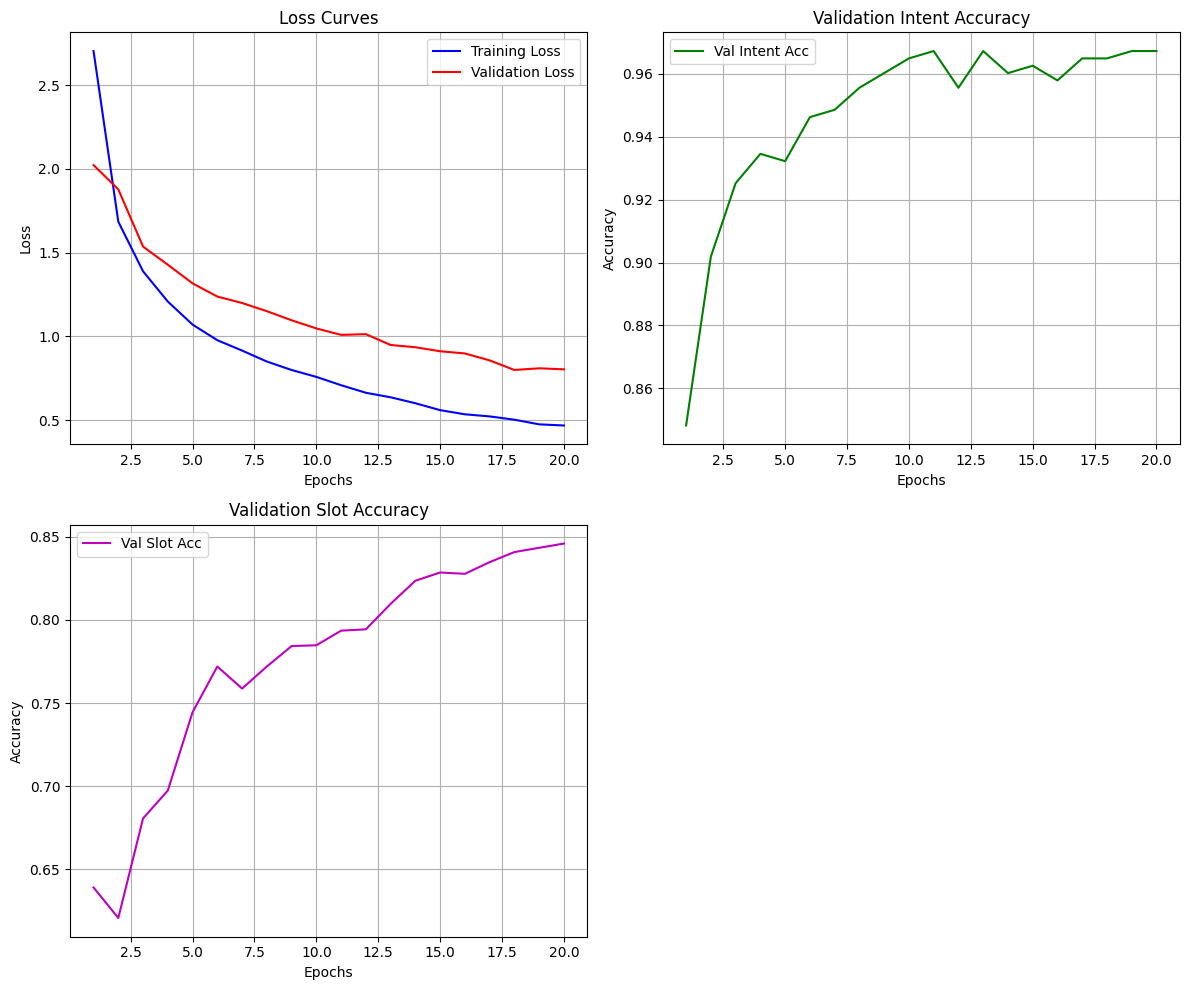

Running Evaluation on Test Set...

--- Generating 5 Analysis Examples ---

Example 1:
Sentence:   BOS what are the coach flights between dallas and baltimore leaving august tenth and returning august <UNK> EOS
True Slots: O O O O B-class_type O O B-fromloc.city_name O B-toloc.city_name O B-depart_date.month_name B-depart_date.day_number O O B-return_date.month_name B-return_date.day_number O
Pred Slots: O O O O O O O B-fromloc.city_name O B-toloc.city_name O B-depart_date.month_name B-depart_date.day_number I-depart_date.day_number O O O O
Intent:     True: atis_flight | Pred: atis_flight
--------------------------------------------------
Example 2:
Sentence:   BOS i want a flight from nashville to seattle that arrives no later than 3 pm EOS
True Slots: O O O O O O B-fromloc.city_name O B-toloc.city_name O O B-arrive_time.time_relative I-arrive_time.time_relative I-arrive_time.time_relative B-arrive_time.time I-arrive_time.time O
Pred Slots: O O O O O O B-fromloc.city_name O B-toloc.ci

In [15]:

# Plotting Function
def plot_all_metrics(train_losses, val_losses, val_intent_accs, val_slot_accs):
    epochs = range(1, len(train_losses) + 1)

    plt.figure(figsize=(12, 10))

    # Loss Curves
    plt.subplot(2, 2, 1)
    plt.plot(epochs, train_losses, 'b-', label='Training Loss')
    plt.plot(epochs, val_losses, 'r-', label='Validation Loss')
    plt.title('Loss Curves')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)

    # Intent Accuracy
    plt.subplot(2, 2, 2)
    plt.plot(epochs, val_intent_accs, 'g-', label='Val Intent Acc')
    plt.title('Validation Intent Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)

    # Slot Accuracy
    plt.subplot(2, 2, 3)
    plt.plot(epochs, val_slot_accs, 'm-', label='Val Slot Acc')
    plt.title('Validation Slot Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

plot_all_metrics(train_losses, val_losses, val_intent_accs, val_slot_accs)

#  Evaluation & Error Analysis Function
def evaluate_and_analyze(model, iterator, show_examples=5):
    model.eval()

    # metric param
    total_intent_correct = 0
    total_intents = 0
    all_true_slots = []
    all_pred_slots = []

    # sample show param
    examples_shown = 0

    print(f"\n--- Generating {show_examples} Analysis Examples ---\n")

    with torch.no_grad():
        for batch in iterator:
            src, slots, lengths, intents = batch
            src, slots, intents = src.to(device), slots.to(device), intents.to(device)

            batch_size = src.shape[0]

            # Greedy Decoding: we dont have TRG producing word to word

            # Encode
            context_hidden, context_cell = model.encoder(src, lengths)

            # Intent Prediction
            intent_logits = model.intent_head(context_hidden)
            pred_intents = intent_logits.argmax(dim=1)

            # Update Intent Metrics
            total_intent_correct += (pred_intents == intents).sum().item()
            total_intents += intents.shape[0]

            # Slot Decoding Loop
            hidden = context_hidden
            cell = context_cell

            # Start with BOS
            BOS_ID = vocab_slots.token2idx['<BOS>']
            input_token = torch.full((batch_size,), BOS_ID, dtype=torch.long).to(device)

            # Store predictions for this batch Max length can be length of src (approx)
            max_len = slots.shape[1]
            batch_preds = []

            for t in range(max_len):
                output, hidden, cell = model.decoder(input_token, hidden, cell)
                best_guess = output.argmax(1) # [batch]
                batch_preds.append(best_guess)
                input_token = best_guess # Feed output as next input (Greedy)

            # Convert list of tensors to [batch, seq_len]
            batch_preds = torch.stack(batch_preds, dim=1)

            #  Process Results for SeqEval & Display
            for i in range(batch_size):
                true_sent_tags = []
                pred_sent_tags = []
                sent_tokens = [] # To show the original words

                length = lengths[i].item()

                for j in range(length):
                    # Original Word
                    word_idx = src[i, j].item()
                    word = vocab_words.idx2token.get(word_idx, '<UNK>')
                    sent_tokens.append(word)

                    # True Slot
                    slot_idx = slots[i, j].item()
                    true_tag = vocab_slots.idx2token.get(slot_idx, 'O')
                    true_sent_tags.append(true_tag)

                    # Pred Slot
                    if j < batch_preds.shape[1]:
                        pred_idx = batch_preds[i, j].item()
                        pred_tag = vocab_slots.idx2token.get(pred_idx, 'O')
                        # If EOS is generated, stop or treat as O
                        if pred_tag == '<EOS>':
                            pred_tag = 'O'
                    else:
                        pred_tag = 'O'
                    pred_sent_tags.append(pred_tag)

                all_true_slots.append(true_sent_tags)
                all_pred_slots.append(pred_sent_tags)

                # Show Examples
                if examples_shown < show_examples:
                    print(f"Example {examples_shown + 1}:")
                    print(f"Sentence:   {' '.join(sent_tokens)}")
                    print(f"True Slots: {' '.join(true_sent_tags)}")
                    print(f"Pred Slots: {' '.join(pred_sent_tags)}")

                    # Intent Info
                    true_intent = vocab_intents.idx2token[intents[i].item()]
                    pred_intent_str = vocab_intents.idx2token[pred_intents[i].item()]
                    print(f"Intent:     True: {true_intent} | Pred: {pred_intent_str}")
                    print("-" * 50)
                    examples_shown += 1

    # Final Calculations
    intent_acc = total_intent_correct / total_intents
    f1 = f1_score(all_true_slots, all_pred_slots)
    report = classification_report(all_true_slots, all_pred_slots)

    return intent_acc, f1, report

# evaluate
print("Running Evaluation on Test Set...")
test_intent_acc, test_slot_f1, test_report = evaluate_and_analyze(model_s2s, test_loader_32, show_examples=5)

print(f"\n>> Intent Detection Test Accuracy: {test_intent_acc*100:.2f}%")
print(f">> Slot Filling F1 Score: {test_slot_f1*100:.2f}%")
print("\n--- Slot Classification Report ---")
print(test_report)


## concetual questions of 1-4:

### Q1 (Section 1-4-1): "What capability has the existence of the decoder added to the network?

The decoder decouples the output length from the input length. In a standard BiLSTM (Part 1-3), the model is constrained to a 1-to-1 mapping (one slot per word). The Encoder-Decoder architecture allows the model to treat the slots as a sequence generation task, potentially handling cases where the number of slots differs from the number of words (though in ATIS, they are usually aligned). It captures the dependencies between the output labels (slots) more explicitly than the input words.

### Q2 (Section 1-4-1): "Why are <BOS> and <EOS> tokens necessary?
< BOS> (Begin of Sentence): The Decoder is an autoregressive model; it needs an initial input to start generating the first slot. Since there is no "previous slot" at the first step, we feed it < BOS>.< EOS> (End of Sentence): This tells the model when to stop generating slots. Without it, the model wouldn't know when the sequence of slots is complete.
### Q3 (Section 1-4-3): "Why is the performance of this network on slot detection weaker than the previous networks?

 The non-aligned Encoder-Decoder loses the explicit 1-to-1 correspondence between the word (e.g., "Boston") and its tag (e.g., "B-fromloc"). The Decoder has to "remember" which word it is currently tagging solely based on the hidden state, which is difficult for long sequences. The previous models (BiRNN/BiLSTM) saw the specific word $x_t$ exactly when predicting slot $y_t$.

 ### Q4 (Section 1-4-3): "In the paper, to fix this problem, a method other than the attention mechanism is proposed. What is that method?

  The paper proposes "Encoder-Decoder with Aligned Inputs". In this method, instead of just feeding the previous slot label $y_{i-1}$ to the decoder, they also feed the explicitly aligned encoder state $h_i$ corresponding to the current word. This re-introduces the alignment information that was lost in the pure Encoder-Decoder approach.
